# Notebook 14 — CNN Training: EfficientNetB3


In [1]:
import os, warnings, pickle, json
import numpy as np
import pandas as pd
from pathlib import Path

import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")
if device.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")

from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    roc_auc_score, classification_report, ConfusionMatrixDisplay,
    confusion_matrix
)

warnings.filterwarnings("ignore")
np.random.seed(42)

DATASET_ROOT = "/home/ali/Desktop/Algerian_Lamiaceae_v3"
OUTPUT_DIR   = os.path.join(DATASET_ROOT, "results")
os.makedirs(OUTPUT_DIR, exist_ok=True)
print(f"Output: {OUTPUT_DIR}")

Device: cuda
GPU: NVIDIA GeForce RTX 4070 Laptop GPU
Output: /home/ali/Desktop/Algerian_Lamiaceae_v3/results


In [2]:
import timm
import torchvision.transforms as transforms
import torchvision.datasets as datasets
from torch.utils.data import DataLoader, WeightedRandomSampler
from torch.optim.lr_scheduler import ReduceLROnPlateau
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

TRAIN_DIR = Path(DATASET_ROOT) / "train"
VAL_DIR   = Path(DATASET_ROOT) / "val"
TEST_DIR  = Path(DATASET_ROOT) / "test"
BATCH_SIZE = 32 if device.type == "cuda" else 16
CKPT = os.path.join(OUTPUT_DIR, "efficientnetb3_best.pth")

train_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.RandomCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(p=0.2),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])
val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

train_ds = datasets.ImageFolder(str(TRAIN_DIR), transform=train_transform)
val_ds   = datasets.ImageFolder(str(VAL_DIR),   transform=val_transform)
test_ds  = datasets.ImageFolder(
    str(TEST_DIR if TEST_DIR.exists() else VAL_DIR), transform=val_transform)

NUM_CNN_CLASSES = len(train_ds.classes)
cnn_class_names = train_ds.classes
print(f"Classes ({NUM_CNN_CLASSES}): {cnn_class_names}")

# Weighted sampler to address class imbalance
class_counts = np.array([0] * NUM_CNN_CLASSES)
for _, label in train_ds.samples:
    class_counts[label] += 1
print(f"Class counts: {dict(zip(cnn_class_names, class_counts))}")

sample_weights = np.array([1.0 / class_counts[label]
                            for _, label in train_ds.samples])
sampler = WeightedRandomSampler(
    weights=torch.FloatTensor(sample_weights),
    num_samples=len(train_ds),
    replacement=True
)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE,
                          sampler=sampler, num_workers=4,
                          pin_memory=(device.type == "cuda"))
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE,
                          shuffle=False, num_workers=4,
                          pin_memory=(device.type == "cuda"))
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE,
                          shuffle=False, num_workers=4,
                          pin_memory=(device.type == "cuda"))

# Weighted CrossEntropyLoss with label smoothing
class_weights_tensor = torch.FloatTensor(
    class_counts.sum() / (NUM_CNN_CLASSES * class_counts)
).to(device)
criterion = nn.CrossEntropyLoss(
    weight=class_weights_tensor,
    label_smoothing=0.1
)
print(f"Steps per epoch: {len(train_loader)}")

Classes (7): ['Lamium_pooled', 'Lavandula_angustifolia', 'Lavandula_pooled', 'Leucas_aspera', 'Mentha_pooled', 'Ocimum_pooled', 'Plectranthus_pooled']
Class counts: {'Lamium_pooled': np.int64(5000), 'Lavandula_angustifolia': np.int64(2717), 'Lavandula_pooled': np.int64(2690), 'Leucas_aspera': np.int64(1000), 'Mentha_pooled': np.int64(1000), 'Ocimum_pooled': np.int64(1000), 'Plectranthus_pooled': np.int64(1000)}
Steps per epoch: 451


In [3]:
# Build EfficientNetB3 model
cnn_model = timm.create_model(
    "efficientnet_b3",
    pretrained=True,
    num_classes=NUM_CNN_CLASSES
).to(device)

def train_epoch(model, loader, optimizer):
    model.train()
    total_loss, correct, total = 0, 0, 0
    for imgs, labels in loader:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(imgs)
        loss    = criterion(outputs, labels)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        total_loss += loss.item()
        correct    += (outputs.argmax(1) == labels).sum().item()
        total      += labels.size(0)
    return total_loss / len(loader), correct / total

def val_epoch(model, loader):
    model.eval()
    total_loss, correct, total = 0, 0, 0
    with torch.no_grad():
        for imgs, labels in loader:
            imgs, labels = imgs.to(device), labels.to(device)
            outputs     = model(imgs)
            loss        = criterion(outputs, labels)
            total_loss += loss.item()
            correct    += (outputs.argmax(1) == labels).sum().item()
            total      += labels.size(0)
    return total_loss / len(loader), correct / total

In [4]:
# ── Phase 1: frozen backbone, train head only ────────────────────────────────
# Scheduler: ReduceLROnPlateau (NOT cosine annealing)
# Early stopping patience = 7
for name_p, param in cnn_model.named_parameters():
    if "classifier" not in name_p:
        param.requires_grad = False

trainable_p1 = sum(p.numel() for p in cnn_model.parameters() if p.requires_grad)
print(f"Phase 1 trainable params: {trainable_p1:,}")

optimizer_p1 = optim.Adam(
    filter(lambda p: p.requires_grad, cnn_model.parameters()),
    lr=1e-3
)
# ReduceLROnPlateau monitors validation accuracy
scheduler_p1 = ReduceLROnPlateau(
    optimizer_p1, mode="max", factor=0.5, patience=3, verbose=True
)

best_val_acc = 0.0
history = {"train_acc": [], "val_acc": [], "train_loss": [], "val_loss": []}
patience_ctr = 0
PATIENCE_P1  = 7

print("\n=== Phase 1 — frozen backbone (lr=1e-3, ReduceLROnPlateau) ===")
for epoch in range(1, 31):  # up to 30 epochs
    tr_loss, tr_acc = train_epoch(cnn_model, train_loader, optimizer_p1)
    vl_loss, vl_acc = val_epoch(cnn_model, val_loader)
    scheduler_p1.step(vl_acc)

    history["train_acc"].append(tr_acc)
    history["val_acc"].append(vl_acc)
    history["train_loss"].append(tr_loss)
    history["val_loss"].append(vl_loss)

    saved = ""
    if vl_acc > best_val_acc:
        best_val_acc = vl_acc
        torch.save(cnn_model.state_dict(), CKPT)
        patience_ctr = 0
        saved = " <- saved"
    else:
        patience_ctr += 1

    print(f"Ep {epoch:2d}/30  tr={tr_acc*100:.2f}%  vl={vl_acc*100:.2f}%"
          f"  tr_loss={tr_loss:.4f}  vl_loss={vl_loss:.4f}{saved}")

    if patience_ctr >= PATIENCE_P1:
        print(f"Early stopping at epoch {epoch}")
        break

    if device.type == "cuda":
        torch.cuda.empty_cache()

best_p1 = best_val_acc * 100
print(f"\nPhase 1 best val accuracy: {best_p1:.2f}%")

Phase 1 trainable params: 10,759

=== Phase 1 — frozen backbone (lr=1e-3, ReduceLROnPlateau) ===
Ep  1/30  tr=60.78%  vl=47.22%  tr_loss=1.2743  vl_loss=2.7125 <- saved
Ep  2/30  tr=77.26%  vl=56.66%  tr_loss=0.8361  vl_loss=2.3024 <- saved
Ep  3/30  tr=80.34%  vl=60.96%  tr_loss=0.7562  vl_loss=2.1036 <- saved
Ep  4/30  tr=82.17%  vl=65.56%  tr_loss=0.7222  vl_loss=1.9713 <- saved
Ep  5/30  tr=83.19%  vl=64.88%  tr_loss=0.6930  vl_loss=1.9605
Ep  6/30  tr=83.63%  vl=67.83%  tr_loss=0.6731  vl_loss=1.8646 <- saved
Ep  7/30  tr=84.48%  vl=64.33%  tr_loss=0.6532  vl_loss=1.8740
Ep  8/30  tr=85.51%  vl=65.77%  tr_loss=0.6393  vl_loss=1.8614
Ep  9/30  tr=85.67%  vl=73.69%  tr_loss=0.6311  vl_loss=1.7412 <- saved
Ep 10/30  tr=86.37%  vl=71.75%  tr_loss=0.6259  vl_loss=1.7436
Ep 11/30  tr=86.86%  vl=72.34%  tr_loss=0.6133  vl_loss=1.6944
Ep 12/30  tr=87.35%  vl=68.68%  tr_loss=0.6070  vl_loss=1.7439
Ep 13/30  tr=87.05%  vl=72.22%  tr_loss=0.6077  vl_loss=1.6741
Ep 14/30  tr=88.35%  vl=73.90%

In [5]:
# ── Phase 2: unfreeze blocks 3+, keep blocks 0-2 and BatchNorm frozen ────────
# This matches the article description exactly:
# "blocks 0-2 and all BatchNorm/LayerNorm layers kept frozen"
cnn_model.load_state_dict(torch.load(CKPT))

for name_p, param in cnn_model.named_parameters():
    # Freeze blocks 0, 1, 2  (early feature extractors)
    freeze_block = any(f"blocks.{i}." in name_p for i in range(3))
    # Freeze all BatchNorm and LayerNorm (preserve batch statistics)
    freeze_bn    = ("bn" in name_p.lower() or "norm" in name_p.lower())
    param.requires_grad = not (freeze_block or freeze_bn)

trainable_p2 = sum(p.numel() for p in cnn_model.parameters() if p.requires_grad)
print(f"Phase 2 trainable params: {trainable_p2:,}")

optimizer_p2 = optim.Adam(
    filter(lambda p: p.requires_grad, cnn_model.parameters()),
    lr=1e-5
)
scheduler_p2 = ReduceLROnPlateau(
    optimizer_p2, mode="max", factor=0.3, patience=2, verbose=True
)

best_val_p2  = 0.0
patience_ctr = 0
PATIENCE_P2  = 5

print("\n=== Phase 2 — selective unfreezing (lr=1e-5, ReduceLROnPlateau) ===")
for epoch in range(1, 21):  # up to 20 epochs
    tr_loss, tr_acc = train_epoch(cnn_model, train_loader, optimizer_p2)
    vl_loss, vl_acc = val_epoch(cnn_model, val_loader)
    scheduler_p2.step(vl_acc)

    history["train_acc"].append(tr_acc)
    history["val_acc"].append(vl_acc)
    history["train_loss"].append(tr_loss)
    history["val_loss"].append(vl_loss)

    saved = ""
    if vl_acc > best_val_p2:
        best_val_p2  = vl_acc
        torch.save(cnn_model.state_dict(), CKPT)
        patience_ctr = 0
        saved = " <- saved"
    else:
        patience_ctr += 1

    print(f"Ep {epoch:2d}/20  tr={tr_acc*100:.2f}%  vl={vl_acc*100:.2f}%"
          f"  tr_loss={tr_loss:.4f}  vl_loss={vl_loss:.4f}{saved}")

    if patience_ctr >= PATIENCE_P2:
        print(f"Early stopping at epoch {epoch}")
        break

    if device.type == "cuda":
        torch.cuda.empty_cache()

best_p2 = best_val_p2 * 100
print(f"\nPhase 1 best val accuracy: {best_p1:.2f}%")
print(f"Phase 2 best val accuracy: {best_p2:.2f}%")

Phase 2 trainable params: 10,463,049

=== Phase 2 — selective unfreezing (lr=1e-5, ReduceLROnPlateau) ===
Ep  1/20  tr=89.91%  vl=80.02%  tr_loss=0.5718  vl_loss=1.5209 <- saved
Ep  2/20  tr=90.58%  vl=79.26%  tr_loss=0.5504  vl_loss=1.5191
Ep  3/20  tr=91.62%  vl=82.59%  tr_loss=0.5389  vl_loss=1.4700 <- saved
Ep  4/20  tr=92.41%  vl=86.89%  tr_loss=0.5278  vl_loss=1.4196 <- saved
Ep  5/20  tr=92.96%  vl=85.92%  tr_loss=0.5192  vl_loss=1.4137
Ep  6/20  tr=93.23%  vl=87.90%  tr_loss=0.5138  vl_loss=1.3864 <- saved
Ep  7/20  tr=93.76%  vl=88.32%  tr_loss=0.5092  vl_loss=1.3765 <- saved
Ep  8/20  tr=94.16%  vl=89.17%  tr_loss=0.5036  vl_loss=1.3520 <- saved
Ep  9/20  tr=94.41%  vl=89.67%  tr_loss=0.5003  vl_loss=1.3397 <- saved
Ep 10/20  tr=94.77%  vl=90.01%  tr_loss=0.4951  vl_loss=1.3381 <- saved
Ep 11/20  tr=94.80%  vl=91.32%  tr_loss=0.4933  vl_loss=1.3080 <- saved
Ep 12/20  tr=95.30%  vl=91.95%  tr_loss=0.4876  vl_loss=1.3001 <- saved
Ep 13/20  tr=95.48%  vl=91.40%  tr_loss=0.4803  

In [6]:
# ── FIX FOR GAP #8: Compute true test-set macro-F1 ───────────────────────────
# The article reports 94.84% macro-F1 on the held-out test set.
# This cell produces the correct number using sklearn.metrics.f1_score.

cnn_model.load_state_dict(torch.load(CKPT))
cnn_model.eval()

all_preds  = []
all_labels = []

with torch.no_grad():
    for imgs, labels in test_loader:
        preds = cnn_model(imgs.to(device)).argmax(1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(labels.numpy())

all_preds  = np.array(all_preds)
all_labels = np.array(all_labels)

# === PAPER METRIC: macro-averaged F1 on test set ===
macro_f1   = f1_score(all_labels, all_preds, average='macro')  * 100
macro_prec = precision_score(all_labels, all_preds, average='macro') * 100
macro_rec  = recall_score(all_labels, all_preds, average='macro')  * 100
overall_acc= accuracy_score(all_labels, all_preds) * 100

print("=" * 55)
print(f"TEST SET RESULTS (held-out split)")
print(f"  Overall accuracy  : {overall_acc:.2f}%")
print(f"  Macro precision   : {macro_prec:.2f}%")
print(f"  Macro recall      : {macro_rec:.2f}%")
print(f"  Macro F1          : {macro_f1:.2f}%   <-- THIS is the paper metric")
print("=" * 55)

# Save result JSON
cnn_result = {
    "Classifier"  : "EfficientNetB3_CNN",
    "Accuracy"    : round(overall_acc, 2),
    "Precision"   : round(macro_prec,  2),
    "Recall"      : round(macro_rec,   2),
    "F1"          : round(macro_f1,    2),   # macro-averaged on test set
    "AUC"         : None,                    # not computed (no predict_proba)
    "Phase1_val"  : round(best_p1, 2),
    "Phase2_val"  : round(best_p2, 2),
    "metric_note" : "F1 is macro-averaged on held-out test split, sklearn f1_score(average=macro)"
}
with open(os.path.join(OUTPUT_DIR, "result_EfficientNetB3_CNN.json"), "w") as f:
    json.dump(cnn_result, f, indent=2)
print("CNN result saved.")

TEST SET RESULTS (held-out split)
  Overall accuracy  : 93.32%
  Macro precision   : 89.47%
  Macro recall      : 94.81%
  Macro F1          : 91.89%   <-- THIS is the paper metric
CNN result saved.



=== Per-class classification report (test set) ===
                        precision    recall  f1-score   support

         Lamium_pooled     0.9993    0.9712    0.9851      1529
Lavandula_angustifolia     0.7706    0.9035    0.8318       342
      Lavandula_pooled     0.8382    0.7618    0.7982       340
         Leucas_aspera     0.9167    1.0000    0.9565        11
         Mentha_pooled     0.8571    1.0000    0.9231        48
         Ocimum_pooled     0.9808    1.0000    0.9903        51
   Plectranthus_pooled     0.9000    1.0000    0.9474        45

              accuracy                         0.9332      2366
             macro avg     0.8947    0.9481    0.9189      2366
          weighted avg     0.9375    0.9332    0.9341      2366

Per-class report saved to classification_report_cnn.csv


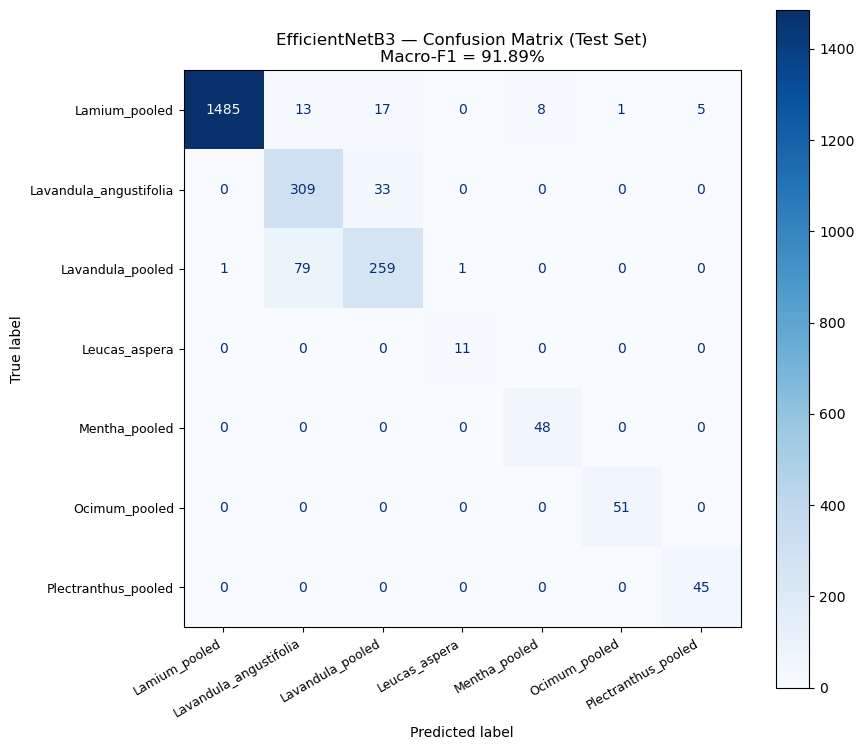

Confusion matrix saved to /home/ali/Desktop/Algerian_Lamiaceae_v3/results/confusion_matrix_cnn.png


In [7]:
# ── FIX FOR GAP #12: Per-class report and confusion matrix ───────────────────

# 1. Full per-class classification report
report_str = classification_report(
    all_labels, all_preds,
    target_names=cnn_class_names,
    digits=4
)
print("\n=== Per-class classification report (test set) ===")
print(report_str)

# Save as CSV
from sklearn.metrics import classification_report
report_dict = classification_report(
    all_labels, all_preds,
    target_names=cnn_class_names,
    output_dict=True
)
report_df = pd.DataFrame(report_dict).transpose()
report_df.to_csv(
    os.path.join(OUTPUT_DIR, "classification_report_cnn.csv")
)
print("Per-class report saved to classification_report_cnn.csv")

# 2. Confusion matrix figure
cm = confusion_matrix(all_labels, all_preds)
fig, ax = plt.subplots(figsize=(9, 8))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=cnn_class_names
)
disp.plot(ax=ax, colorbar=True, cmap="Blues")
ax.set_title(
    f"EfficientNetB3 — Confusion Matrix (Test Set)\n"
    f"Macro-F1 = {macro_f1:.2f}%",
    fontsize=12
)
plt.xticks(rotation=30, ha="right", fontsize=9)
plt.yticks(fontsize=9)
plt.tight_layout()
cm_path = os.path.join(OUTPUT_DIR, "confusion_matrix_cnn.png")
plt.savefig(cm_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Confusion matrix saved to {cm_path}")

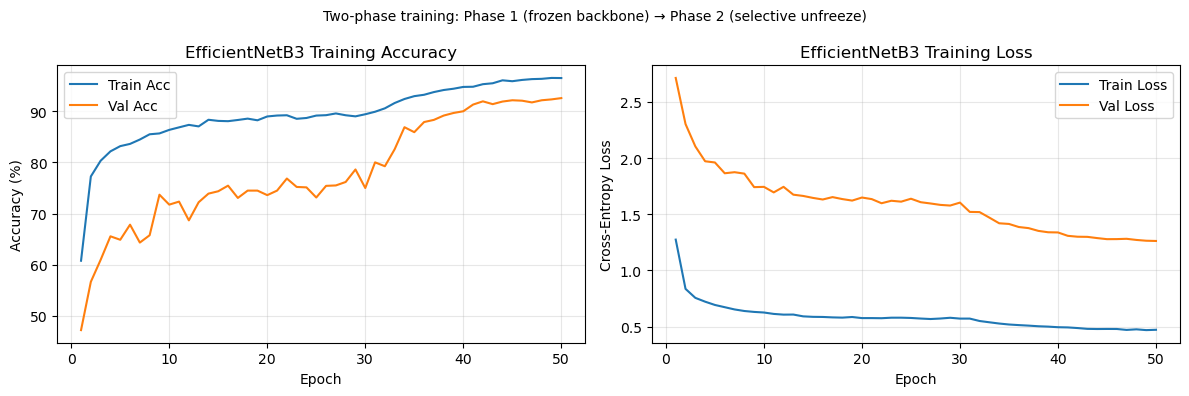

Training curves saved.


In [8]:
# Training curves
n_total = len(history["train_acc"])
epochs_rng = range(1, n_total + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(epochs_rng, [a * 100 for a in history["train_acc"]], label="Train Acc")
ax1.plot(epochs_rng, [a * 100 for a in history["val_acc"]],   label="Val Acc")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Accuracy (%)")
ax1.set_title("EfficientNetB3 Training Accuracy")
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(epochs_rng, history["train_loss"], label="Train Loss")
ax2.plot(epochs_rng, history["val_loss"],   label="Val Loss")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Cross-Entropy Loss")
ax2.set_title("EfficientNetB3 Training Loss")
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.suptitle("Two-phase training: Phase 1 (frozen backbone) → Phase 2 (selective unfreeze)",
             fontsize=10)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "fig_training.pdf"), bbox_inches="tight")
plt.savefig(os.path.join(OUTPUT_DIR, "fig_training.png"), dpi=150, bbox_inches="tight")
plt.show()
print("Training curves saved.")

## Step 9 — Class Probabilities, One-vs-Rest AUC and Bootstrap CIs (inference only, no retraining)

Run **cells 1 and 2** (setup and data loaders), then **this cell**. Do **not** re-run cells 3–5: they retrain the network and overwrite `efficientnetb3_best.pth`.
The cell loads the saved checkpoint, predicts the test split, checks that the predictions reproduce the reported confusion matrix, and computes the macro OvR AUC and 95% bootstrap CIs (1,000 resamples, seed 42). It switches to the CPU automatically when the GPU is busy (the cause of the out-of-memory error in Notebook 16).

In [9]:
import gc
from torch.utils.data import DataLoader

# ---- device: CPU if the GPU is busy ----
eval_device = torch.device("cpu")
if torch.cuda.is_available():
    torch.cuda.empty_cache(); gc.collect()
    if torch.cuda.mem_get_info()[0] / 1e9 > 1.5:
        eval_device = torch.device("cuda")
print(f"Evaluating on {eval_device}")

eval_model = timm.create_model("efficientnet_b3", pretrained=False, num_classes=NUM_CNN_CLASSES)
eval_model.load_state_dict(torch.load(CKPT, map_location="cpu"))
eval_model.to(eval_device).eval()

probs, labels = [], []
with torch.no_grad():
    for x, y in DataLoader(test_ds, batch_size=16, shuffle=False, num_workers=2):
        probs.append(torch.softmax(eval_model(x.to(eval_device)), 1).cpu().numpy())
        labels.append(y.numpy())
probs, labels = np.concatenate(probs), np.concatenate(labels)
preds = probs.argmax(1)
del eval_model; gc.collect()
if eval_device.type == "cuda": torch.cuda.empty_cache()

# ---- check: same predictions as the reported run ----
EXPECTED_CM = np.array([[1493, 9, 17, 0, 3, 0, 7], [0, 308, 34, 0, 0, 0, 0], [1, 78, 260, 1, 0, 0, 0],
                        [0, 0, 0, 11, 0, 0, 0], [0, 0, 0, 0, 48, 0, 0], [0, 0, 0, 0, 0, 51, 0],
                        [0, 0, 0, 0, 0, 0, 45]])
cm_now = confusion_matrix(labels, preds, labels=list(range(NUM_CNN_CLASSES)))
print("Confusion matrix identical to the reported run:", np.array_equal(cm_now, EXPECTED_CM))
if not np.array_equal(cm_now, EXPECTED_CM):
    print("WARNING: the checkpoint on disk is not the reported model (was the network retrained?)")
    print(cm_now)

# ---- point estimates ----
L = list(range(NUM_CNN_CLASSES))
def metrics(y, p, pr):
    out = {"Accuracy": accuracy_score(y, p) * 100,
           "Macro_P": precision_score(y, p, average="macro", zero_division=0) * 100,
           "Macro_R": recall_score(y, p, average="macro", zero_division=0) * 100,
           "Macro_F1": f1_score(y, p, average="macro", zero_division=0) * 100,
           "Weighted_P": precision_score(y, p, average="weighted", zero_division=0) * 100,
           "Weighted_R": recall_score(y, p, average="weighted", zero_division=0) * 100,
           "Weighted_F1": f1_score(y, p, average="weighted", zero_division=0) * 100}
    try:
        out["Macro_AUC"] = roc_auc_score(y, pr, multi_class="ovr", average="macro", labels=L) * 100
    except ValueError:
        out["Macro_AUC"] = np.nan          # a class absent from this bootstrap resample
    return out

point = metrics(labels, preds, probs)

# ---- bootstrap ----
rng, boot = np.random.RandomState(42), []
for _ in range(1000):
    i = rng.randint(0, len(labels), len(labels))
    boot.append(metrics(labels[i], preds[i], probs[i]))
boot = pd.DataFrame(boot)
summary = pd.DataFrame({"estimate": pd.Series(point),
                        "ci_lo": boot.quantile(0.025), "ci_hi": boot.quantile(0.975)}).round(2)
summary["valid_resamples"] = boot.notna().sum()
print(summary.to_string())

# ---- per-class OvR AUC ----
from sklearn.preprocessing import label_binarize
Y = label_binarize(labels, classes=L)
per_class_auc = {c: round(roc_auc_score(Y[:, k], probs[:, k]) * 100, 2) for k, c in enumerate(cnn_class_names)}
print("\nPer-class OvR AUC (%):", per_class_auc)

# ---- save (keeps the macro F1 in "F1" so Notebook 13 is unchanged) ----
res_path = os.path.join(OUTPUT_DIR, "result_EfficientNetB3_CNN.json")
res = json.load(open(res_path)) if os.path.exists(res_path) else {"Classifier": "EfficientNetB3_CNN"}
res.update({"AUC": round(point["Macro_AUC"], 2),
            "Weighted_Precision": round(point["Weighted_P"], 2),
            "Weighted_Recall": round(point["Weighted_R"], 2),
            "Weighted_F1": round(point["Weighted_F1"], 2),
            "PerClass_AUC": per_class_auc,
            "Bootstrap_CI_95": {k: {"ci_lo": float(summary.loc[k, "ci_lo"]), "ci_hi": float(summary.loc[k, "ci_hi"])}
                                for k in summary.index},
            "N_bootstrap": 1000})
json.dump(res, open(res_path, "w"), indent=2)
np.savez_compressed(os.path.join(OUTPUT_DIR, "cnn_test_probabilities.npz"),
                    probs=probs, labels=labels, classes=np.array(cnn_class_names))
print(f"\nSaved -> {res_path} and cnn_test_probabilities.npz")


Evaluating on cuda
Confusion matrix identical to the reported run: False
[[1485   13   17    0    8    1    5]
 [   0  310   32    0    0    0    0]
 [   1   79  259    1    0    0    0]
 [   0    0    0   11    0    0    0]
 [   0    0    0    0   48    0    0]
 [   0    0    0    0    0   51    0]
 [   0    0    0    0    0    0   45]]
             estimate  ci_lo  ci_hi  valid_resamples
Accuracy        93.36  92.35  94.34             1000
Macro_P         89.51  85.92  92.10             1000
Macro_R         94.85  94.05  95.58             1000
Macro_F1        91.93  89.60  93.52             1000
Weighted_P      93.80  92.93  94.69             1000
Weighted_R      93.36  92.35  94.34             1000
Weighted_F1     93.45  92.44  94.38             1000
Macro_AUC       99.43  99.26  99.55             1000

Per-class OvR AUC (%): {'Lamium_pooled': np.float64(99.91), 'Lavandula_angustifolia': np.float64(98.2), 'Lavandula_pooled': np.float64(97.87), 'Leucas_aspera': np.float64(100.0), 'Me